# Digital Soil Organic Carbon Mapping — Dhanolti, Uttarakhand

**Model:** Random Forest (R method) + improved blend: RF with oblique coordinates + SVR | **Splits:** 70:30 & 80:20 | **CV:** 5-fold, 10-fold, LOOCV | **Framework:** SCORPAN-E, 30 m

Walkthrough of [`soc_master.py`](soc_master.py), the Python port of [`SOC_MASTER.R`](../SOC_MASTER.R). All logic lives in the scripts; this notebook calls them step by step and shows the results inline.

### How the R behaviour is reproduced

| R | Python (`soc_master.py`) |
|---|---|
| `set.seed()` + `sample()` | `RRNG`: bit-exact R Mersenne-Twister + Rejection sampling |
| `caret::createDataPartition` | `create_data_partition`: **same train/test rows as R** for the same seed |
| `randomForest(nodesize = 5)` | `RForest`: bootstrap rows duplicated like R, `mtry` per node, OOB |
| `rf$importance[, "%IncMSE"]` | `oob_inc_mse`: per-tree OOB permutation, unscaled |
| `caret::train(metric = "RMSE")` | `tune_mtry`: mean fold RMSE, Rsquared = cor², CV_R2 = max over the grid |
| `terra::mask(touches = TRUE)` | `rasterio` mask with `all_touched = True` |

### Results: R vs Python (same data, same seed, same train/test rows)

| | R `SOC_MASTER.R` | Python, R method | Python, blend |
|---|---|---|---|
| 80:20 holdout Test R² | 0.414 | 0.464 | 0.483 |
| 70:30 holdout Test R² | 0.347 | 0.330 | 0.292 |
| Train R² (80:20 / 70:30) | 0.824 / 0.797 | 0.823 / 0.797 | — |
| Best Test R² | 0.438 (80:20, LOOCV) | 0.441 (80:20, 10-fold) | 0.483 |
| Features kept (%IncMSE > 0) | 19 | 21 | 21 |
| **Mean Test R², 50 random 80:20 splits** | — | 0.057 | **0.138** |

Python cannot replay R's internal `randomForest` random draws, so borderline features (|%IncMSE| < 0.01) and single-split scores differ by noise. A single 16–24-sample test set swings by ±0.2 R², so judge models on the repeated-split mean.

### Before you run
Python **3.11 or 3.12** (geospatial wheels). From `scripts/`: `pip install -r requirements.txt`. Data goes in `data/` next to `scripts/` (CSV, `rasters/`, `boundary/`).

## 0 — Setup
Settings are module globals: change them here before running later cells (e.g. `sm.FINAL_MODEL = "RF"` reproduces the R map method exactly).

In [1]:
import io, os, sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

sys.path.insert(0, str(Path().resolve()))      # notebook lives next to soc_master.py
import soc_master as sm

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def show(name, width=1100):
    # downscaled copy keeps the notebook small; full-resolution PNGs stay in output/
    im = PILImage.open(sm.OUT_DIR / name)
    im.thumbnail((width, width))
    buf = io.BytesIO()
    im.save(buf, "PNG")
    display(Image(buf.getvalue()))


os.chdir(sm.PROJECT_DIR)
sm.OUT_DIR.mkdir(exist_ok=True)
print("Settings:", dict(SEED=sm.SEED, N_TREE=sm.N_TREE, NODESIZE=sm.NODESIZE,
                        FINAL_MODEL=sm.FINAL_MODEL, N_REPEATS=sm.N_REPEATS))

Settings: {'SEED': 42, 'N_TREE': 1000, 'NODESIZE': 5, 'FINAL_MODEL': 'Blend', 'N_REPEATS': 50}


## 1 — Load & clean data
Drop ID/coordinate columns, keep 0 < SOC < 25, remove near-zero-variance columns, 3×IQR outlier filter on SOC, median imputation, keep the 27 predictors that have rasters. Sample coordinates are kept aside (UTM 44N) for the blend.

In [2]:
model_df, feats, xy = sm.load_clean_data()
model_df.describe().T.round(3)

[ 1/6 ] LOADING & CLEANING DATA
---------------------------------------------
Raw data: 80 rows | 53 cols
Dropped: sno, lat, long
Clean dataset: 80 samples | 27 predictors with rasters
SOC: mean=2.83 | sd=1.17 | min=0.20 | max=5.84



,count,mean,std,min,25%,50%,75%,max
soc,80.0,2.830,1.171,0.201,2.028,2.880,3.690,5.840
slope_1,80.0,0.396,0.184,0.000,0.262,0.384,0.538,0.784
twi_1,80.0,12.505,0.759,11.789,12.185,12.338,12.582,17.957
elevation_1,80.0,1677.850,298.217,871.000,1559.000,1698.500,1800.000,2501.000
aspect_1,80.0,3.230,1.740,0.029,1.807,3.520,4.559,6.283
p_curvature_1,80.0,-0.000,0.002,-0.004,-0.001,-0.000,0.001,0.004
pl_curvature_1,80.0,0.000,0.002,-0.007,-0.001,0.000,0.001,0.005
mat_celsius,80.0,1.622,0.146,1.244,1.562,1.612,1.686,2.008
map_mm,80.0,2195.338,36.101,2127.000,2167.500,2198.000,2219.500,2285.000
precip_seasonality,80.0,134.924,5.691,114.662,133.994,135.522,137.345,144.848


### R parity check
Values produced by R 4.6.1 + caret 7.1.0 with `set.seed(42)`: random numbers and the train/test rows of both splits.

In [3]:
from test_r_parity import test_rng, test_caret
test_rng()
test_caret()
print("R parity OK — same random numbers and same train/test rows as R")

R parity OK — same random numbers and same train/test rows as R


## 2 — Feature selection
As in `SOC_MASTER.R`: 500-tree RF on all 27 predictors (`mtry = floor(sqrt(27))`), keep variables with OOB %IncMSE > 0.

[ 2/6 ] FEATURE SELECTION — RF %IncMSE
---------------------------------------------
          Variable  IncMSE  NodePurity
          ndvi_max  0.1152      8.4053
    ndvi_intercept  0.1070      6.9733
    dist_to_stream  0.1006      7.1568
precip_seasonality  0.0665      4.8037
      nitrogen_gkg  0.0555      4.3402
       mat_celsius  0.0464      4.4246
       elevation_1  0.0369      3.5064
          BD_kgdm3  0.0366      3.9892
          sand_pct  0.0260      3.4310
              SAVI  0.0248      3.4591
 winter_ndvi_slope  0.0222      3.9928
         lithology  0.0184      1.3422
               EVI  0.0148      3.5229
        ndvi_slope  0.0123      3.5898
          silt_pct  0.0111      3.4365
              NDVI  0.0110      3.5818
              NDWI  0.0062      3.0467
          pH_water  0.0019      1.9833
     p_curvature_1  0.0016      2.5393
             twi_1  0.0014      5.2121
              LULC  0.0004      0.6825
          clay_pct -0.0020      3.2002
monsoon_ndvi_slope

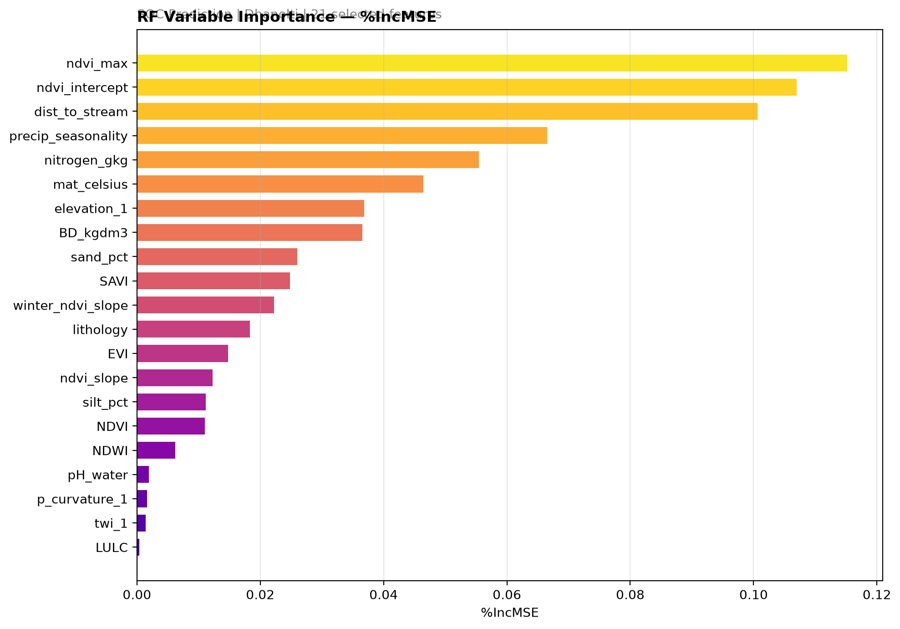

In [4]:
sel = sm.select_features(model_df, feats)
show("Plot_Feature_Importance.png", 900)

## 3 — Model training
For each split: a baseline RF (`mtry = floor(sqrt(p))`) for holdout/train metrics, then `mtry` tuned by 5-fold, 10-fold and LOOCV CV (caret style, lowest RMSE). `Blend_*` columns are the improved blend on the same test rows (not mtry-tuned, so equal across the CV rows of a split).

In [5]:
res = sm.train_models(model_df[["soc"] + sel], sel, xy)

[ 3/6 ] MODEL TRAINING — RF with 70:30 & 80:20 | 5-fold, 10-fold, LOOCV
---------------------------------------------
mtry grid: [2, 4, 6, 7]

70:30 | Train: 56 | Test: 24
  Holdout Test  R2=0.330 RMSE=0.997   | Blend R2=0.292 RMSE=1.025
  Holdout Train R2=0.797 RMSE=0.514
  CV: 5-fold   ... mtry=2 | Test R2=0.318 | CV R2=0.088
  CV: 10-fold  ... mtry=7 | Test R2=0.338 | CV R2=0.233
  CV: LOOCV    ... mtry=2 | Test R2=0.318 | CV R2=0.011

80:20 | Train: 64 | Test: 16
  Holdout Test  R2=0.464 RMSE=0.883   | Blend R2=0.483 RMSE=0.867
  Holdout Train R2=0.823 RMSE=0.485
  CV: 5-fold   ... mtry=2 | Test R2=0.407 | CV R2=0.108
  CV: 10-fold  ... mtry=6 | Test R2=0.441 | CV R2=0.207
  CV: LOOCV    ... mtry=6 | Test R2=0.441 | CV R2=0.027

=== ALL MODEL RESULTS ===
Split      CV  Best_mtry  Train_R2  Train_RMSE  Test_R2  Test_RMSE  Test_MAE  Test_RPIQ  CV_R2  CV_RMSE  Blend_Test_R2  Blend_Test_RMSE
80:20 10-fold          6     0.823       0.485    0.441      0.901     0.775      1.602  0.207 

,Split,CV,Best_mtry,Train_R2,Train_RMSE,Test_R2,Test_RMSE,Test_MAE,Test_RPIQ,CV_R2,CV_RMSE,Blend_Test_R2,Blend_Test_RMSE
0,70:30,5-fold,2,0.797,0.514,0.318,1.006,0.781,1.616,0.088,1.199,0.292,1.025
1,70:30,10-fold,7,0.797,0.514,0.338,0.991,0.763,1.640,0.233,1.157,0.292,1.025
2,70:30,LOOCV,2,0.797,0.514,0.318,1.006,0.781,1.616,0.011,1.211,0.292,1.025
3,80:20,5-fold,2,0.823,0.485,0.407,0.928,0.788,1.555,0.108,1.201,0.483,0.867
4,80:20,10-fold,6,0.823,0.485,0.441,0.901,0.775,1.602,0.207,1.144,0.483,0.867
5,80:20,LOOCV,6,0.823,0.485,0.441,0.901,0.775,1.602,0.027,1.162,0.483,0.867


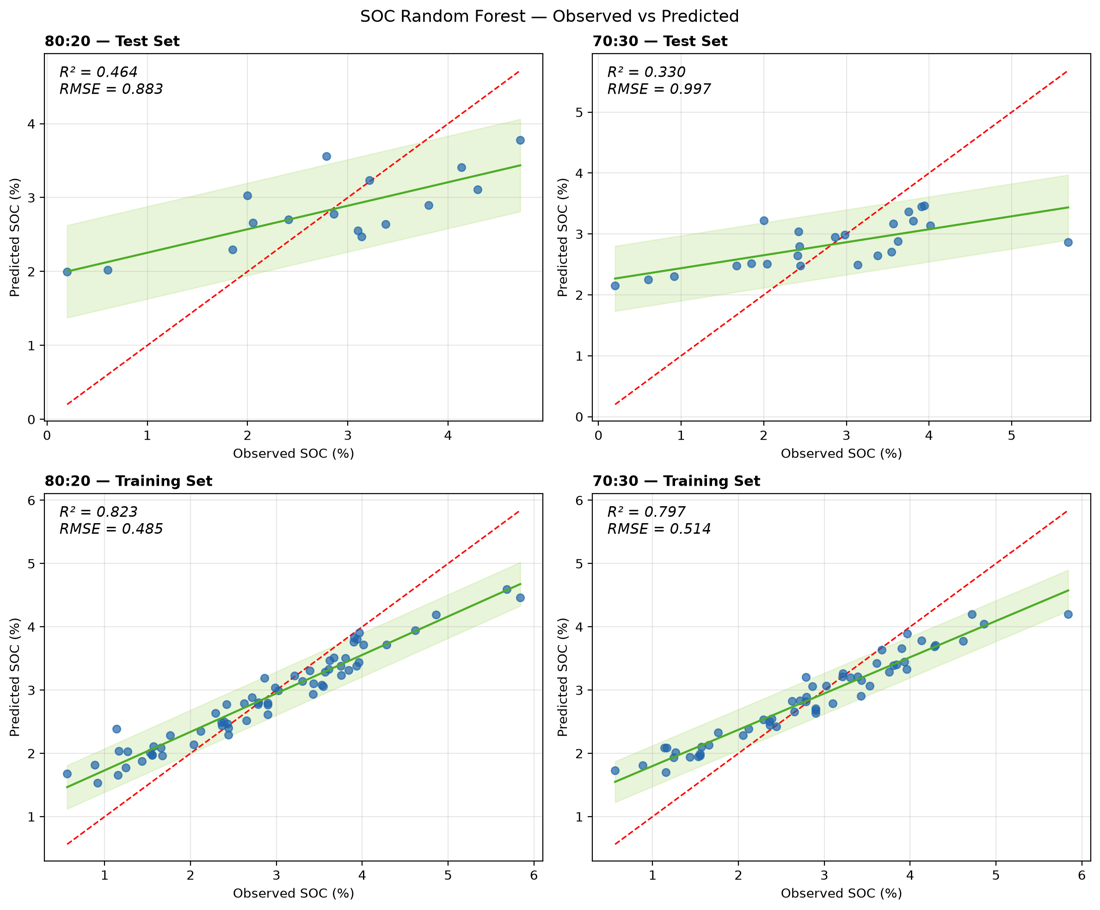

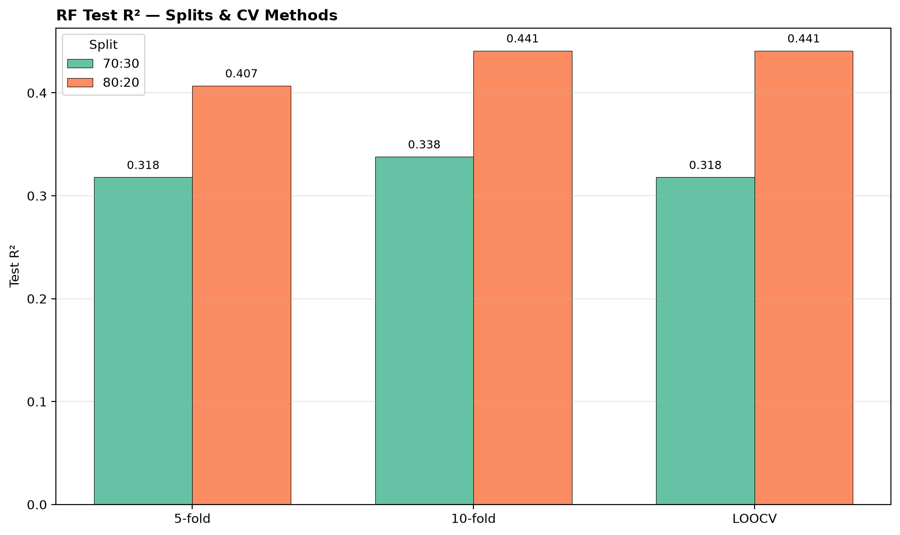

In [6]:
display(res)
show("Plot_ObsVsPred.png")
show("Plot_Model_Comparison.png", 900)

## 4 — Best model
Same rule as R: highest Test R², ties broken by CV R².

In [7]:
best = res.sort_values(["Test_R2", "CV_R2"], ascending=False).iloc[0].to_dict()
pd.Series(best)

Split                80:20
CV                 10-fold
Best_mtry                6
Train_R2             0.823
Train_RMSE           0.485
Test_R2              0.441
Test_RMSE            0.901
Test_MAE             0.775
Test_RPIQ            1.602
CV_R2                0.207
CV_RMSE              1.144
Blend_Test_R2        0.483
Blend_Test_RMSE      0.867
dtype: object

## 4b — Robust check
A single 16-sample test set is mostly luck. This repeats the R-style 80:20 split 50 times, redoing feature selection inside each training set so test rows never leak into selection.

In [8]:
rob = sm.robust_eval(model_df, feats, xy)
rob.describe().round(3)


[ 4b ] ROBUST CHECK — 50 R-style 80:20 splits, features re-selected per split
---------------------------------------------
Mean test R2  RF: 0.057 | Blend: 0.138 | gain +0.081 ± 0.015 (SE) | blend wins 80% of splits


,Seed,RF_Test_R2,Blend_Test_R2
count,50.000,50.000,50.000
mean,25.500,0.057,0.138
std,14.577,0.239,0.170
min,1.000,-0.707,-0.333
25%,13.250,-0.074,0.043
50%,25.500,0.061,0.146
75%,37.750,0.175,0.219
max,50.000,0.465,0.470


## 5 — Spatial prediction & maps
Models retrained on all 80 samples; rasters aligned to `slope_1.tif` (30 m, UTM 44N), predicted, clipped to the boundary. Uncertainty = SD across the 1000 trees of the mapping RF.

In [9]:
sm.map_soc(model_df, sel, best, rob, xy)


[ 5/6 ] SPATIAL PREDICTION & MAPPING
---------------------------------------------
Reference: EPSG:32644 | 30 m | 498 x 448 px
Final RF on ALL 80 samples | mtry=6 | 21 predictors
Final RF OOB R2=0.111 | OOB RMSE=1.104

══════════════════════════════════════════════════
  Area (ha)                     : 11789.6
  Min SOC (%)                   : 2.768
  Max SOC (%)                   : 3.406
  Mean SOC (%)                  : 3.142
  Median SOC (%)                : 3.149
  Std Dev (%)                   : 0.071
  Mean Uncertainty SD (%)       : 1.418
  OOB R2 (RF)                   : 0.111
  OOB RMSE (RF)                 : 1.104
  Final Model                   : Blend
  Best Split                    : 80:20
  Best CV                       : 10-fold
  Best mtry                     : 6
  Test R2 (RF)                  : 0.441
  Test RMSE (RF)                : 0.901
  Test R2 (Blend)               : 0.483
  Test RMSE (Blend)             : 0.867
  Mean Test R2 RF (50 splits)   : 0.057
  Mean Te

,Metric,Value
0,Area (ha),11789.6
1,Min SOC (%),2.768
2,Max SOC (%),3.406
3,Mean SOC (%),3.142
4,Median SOC (%),3.149
5,Std Dev (%),0.071
6,Mean Uncertainty SD (%),1.418
7,OOB R2 (RF),0.111
8,OOB RMSE (RF),1.104
9,Final Model,Blend


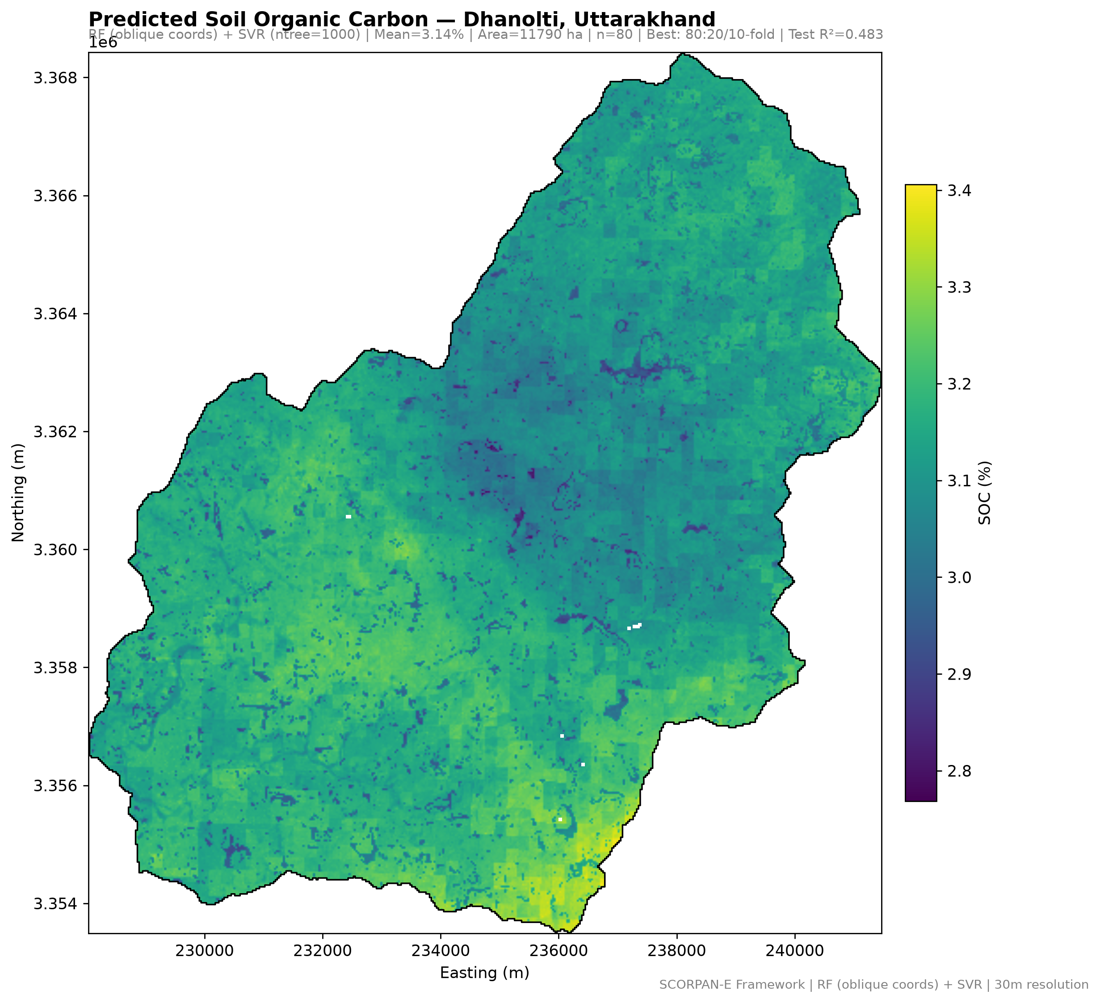

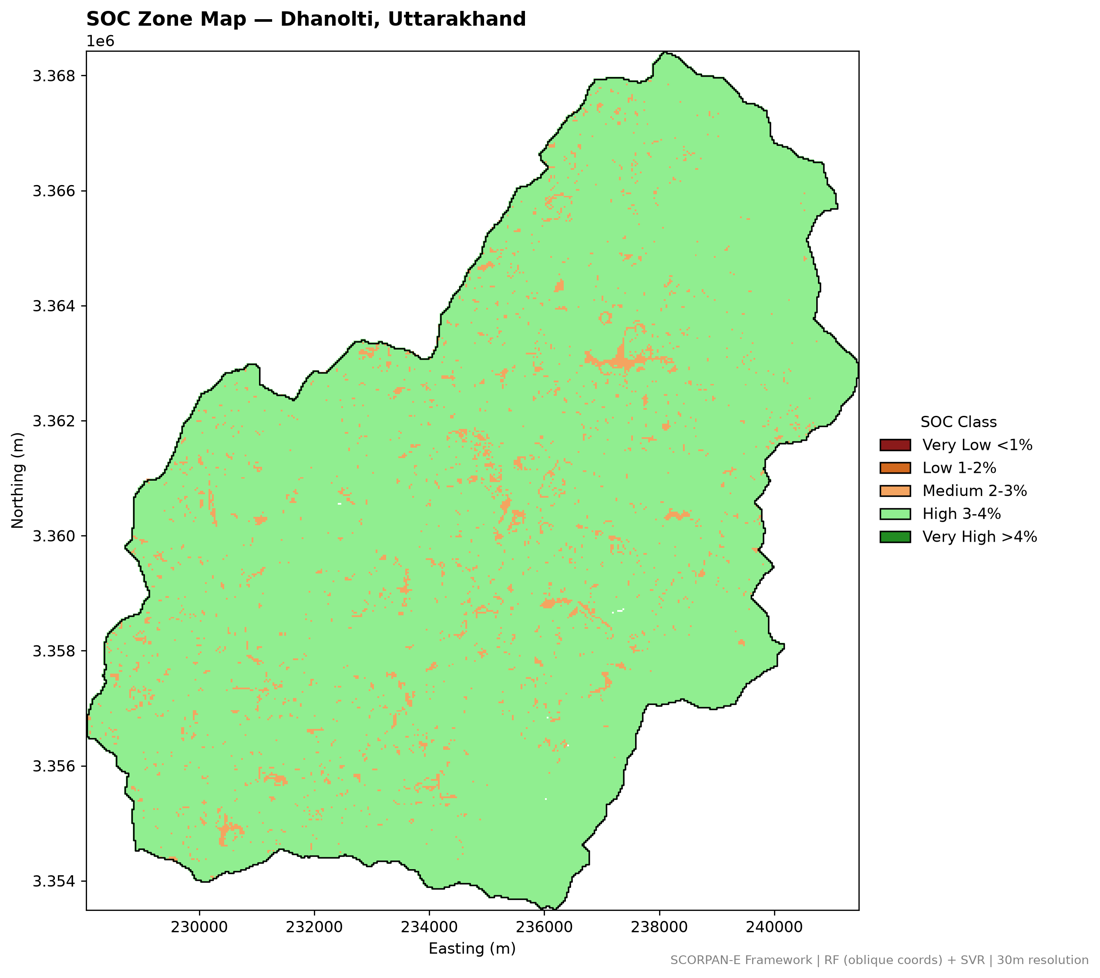

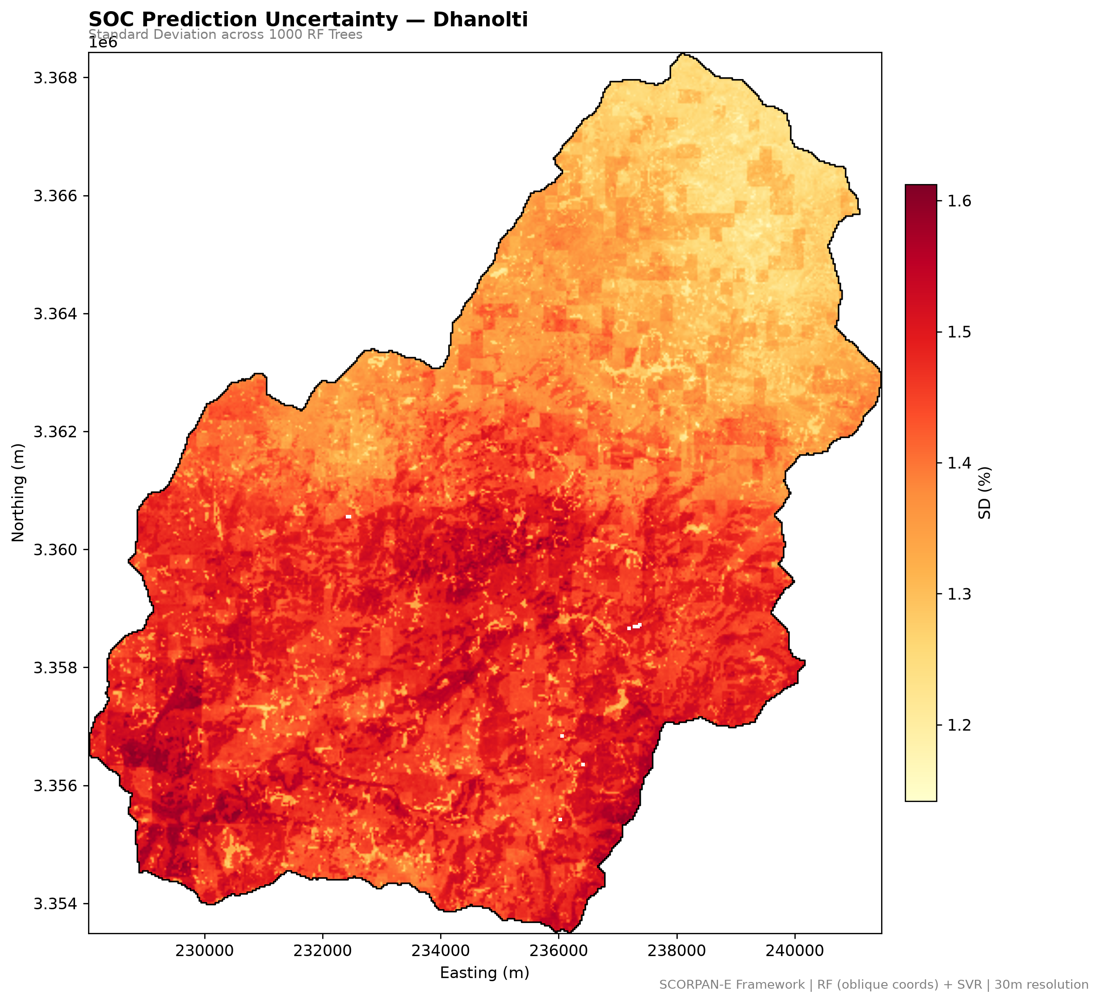

In [10]:
display(pd.read_csv(sm.OUT_DIR / "SOC_Map_Summary.csv"))
show("SOC_Map.png")
show("SOC_Zone_Map.png")
show("SOC_Uncertainty_Map.png")

## 6 — Spatial validation
Random vs spatially blocked 5-fold CV (blocks = k-means clusters of sample locations), 20 repetitions. Which one estimates *map* accuracy depends on how far map pixels are from samples, compared with how far CV test points are from training points (Milà et al. 2022).

In [11]:
import spatial_validation
summ, dsum = spatial_validation.run()
display(summ)
display(dsum)

,CV,Model,Mean_R2,SD_R2,Mean_RMSE
0,Random 5-fold,Blend,0.141,0.044,1.078
1,Random 5-fold,RF (R method),0.073,0.039,1.120
2,Random 5-fold,RF+SVR,0.110,0.045,1.098
3,Spatial blocks 5-fold,Blend,-0.303,0.043,1.329
4,Spatial blocks 5-fold,RF (R method),-0.279,0.035,1.316
5,Spatial blocks 5-fold,RF+SVR,-0.268,0.031,1.311


,P10 (m),P25 (m),P50 (m),P75 (m),P90 (m)
CV test -> train (Random),364.0,535.0,687.0,1076.0,1451.0
CV test -> train (Spatial blocks),1159.0,1793.0,2426.0,3504.0,4507.0
Map pixel -> sample,220.0,367.0,605.0,936.0,1330.0


## Notes
- **Map accuracy.** Map pixels are a median 605 m (90th percentile 1.3 km) from the nearest sample, which matches random CV (687 m / 1.5 km), not spatial blocks (2.4 km / 4.5 km). So random-split CV is the estimate for this map: test R² ≈ 0.06–0.07 for RF, ≈ 0.14 for the blend.
- **Transfer to new areas fails.** With whole regions held out, every model scores R² < 0, and the coordinate blend scores lowest. Do not apply the model outside the sampled watershed.
- **0.438 / 0.483 come from one favourable split.** Report the repeated-split means alongside them.
- The R pipeline selects features on all 80 samples (test rows included); the holdout numbers in step 3 inherit that optimism. Steps 4b and 6 do not.
- Tried and rejected: log/sqrt SOC, TPI/TRI, residual kriging, XGBoost/GBM, GPR, PLS/Ridge, kNN, tuned SVR. Extra CSV covariates (NDMI, BSI, NDVI statistics, CEC…) would help, but they have no rasters, so they can't be mapped.
- Set `sm.FINAL_MODEL = "RF"` in step 0 for the R map method.